In [2]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths
from matplotlib.patches import PathPatch

In [3]:
df = pd.read_csv('SFC_ITScore_Stim.csv')
#df = df.drop('Cups Hab', 1)
print(df)

   Group       CNO    Saline Control
0      1  0.671203  0.311558       n
1      2  0.226196  0.685699       n
2      3  0.439601  0.706415       n
3      4 -0.112231  0.243996       n
4      5 -0.164544  0.661614       n
5      6  0.859600 -0.241204       n
6      7  0.477643  0.399788       n
7      8  0.213873  0.310464       n
8      9  0.832233  0.518843       n
9     10  0.358505 -0.345203       n


In [4]:
data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
#print(newdf)

def map_half(i,num):
    if(i < num/2):
        return 0
    return 1

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


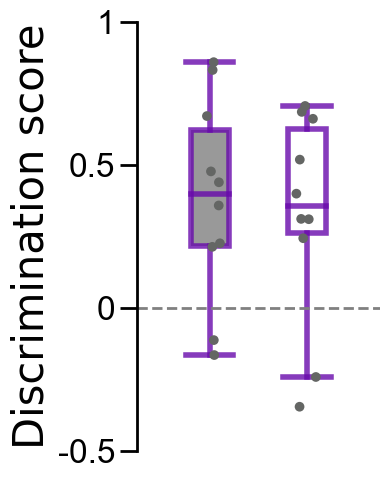

In [7]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}

text_boxplot = ['','****']

text_boxplot = ['','***']
colors = ["#646664","#646664"]
colors_boxplot = ['#680aab', '#680aab']
colors_boxplot_filling = ["grey",'none']


ax = sns.stripplot(
    data=newdf,
    hue='Experimental Condition',
    size=7,
    y='Left preference',
    x='control',
    palette=colors,
    jitter=0.09,
    dodge=True
)


locs = ["upper left"]
boxplot = sns.boxplot(
    data=newdf,
    hue='Experimental Condition',
    y='Left preference',
    x='control',
    palette=colors_boxplot,
    fliersize=0,
    linewidth=4,
    **PROPS
)
plt.axhline(linewidth=2, color='grey',ls='--')


ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)


#CHANGE BOXPLOT STYLE

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches


for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[map_half(i,len(box_patches))]
    col_fill = colors_boxplot_filling[map_half(i,len(box_patches))]
    facecolor = col_fill if i%1==0 else 'None'
    patch.set_edgecolor(col)
    patch.set_facecolor(facecolor)
    
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        
        
#END CHANGE BOXPLOT STYLE

ax.set_ylim([-0.5,1])


plt.legend([],[], frameon=False)
#ax.set_xticks([1,4,7])
#ax.set_xticklabels(['Social 1','Social 2','Recall'], fontsize = 26)
ax.set_xlabel('')
ax.set_xticks([])

ax.set_ylabel('Discrimination score', fontsize = 30)
ax.set_yticks([-0.5,0,0.5,1], fontname='Arial')
ax.set_yticklabels(['-0.5','0','0.5','1'],fontname='Arial')


ax.tick_params(axis='y', which='major', direction='out',length=12, labelsize=24, width=2)

fig = ax.get_figure()
adjust_box_widths(fig, 0.4)
fig.set_size_inches(4,4.9)

plt.tight_layout()
fig.tight_layout()
fig.savefig("SFC_Score_Stim.jpg",dpi=600,bbox_inches='tight')
plt.savefig('SFC_Score_Stim.eps', dpi=600, format='eps')

